# 04 - End-to-end: dataset -> baseline -> latitude analysis -> tangent -> rotation -> fusion -> evaluation -> ablation

Part A runs the whole method live on one panorama. Part B loads the complete experiment (`python run_experiment.py --config configs/default.yaml`).

In [1]:
import os, sys, json
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
sys.path.insert(0, ROOT); os.chdir(ROOT)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
RES = 'results/midas_dpt_hybrid_synthetic'   # change to e.g. results/dap_stanford2d3d after running DAP
REP = os.path.join(RES, 'report_align-all')
def show(p, w=900):
    p = os.path.join(RES, p) if not os.path.exists(p) else p
    display(Image(filename=p, width=w)) if os.path.exists(p) else print('missing', p)

## A. Live run on one panorama

In [2]:
from experiments.common import load_config, make_dataset
from models.depth_model import build_model
from inference.pipeline import DistortionAwareInference, MethodConfig
from evaluation.evaluation import Evaluator
cfg = load_config('configs/default.yaml'); s = make_dataset(cfg)[1]
model = build_model(dict(cfg['model']))
dai = DistortionAwareInference(model)
ev = Evaluator(model.spec.space, 'affine')
cfgs = [MethodConfig('baseline'), MethodConfig('tangent', lat_threshold=45, fusion='cosine'),
        MethodConfig('rotation', rotations=[[0,90,0],[90,90,0]], fusion='cosine'),
        MethodConfig('hybrid', rotations=[[0,90,0],[90,90,0]], fusion='cosine')]
for c in cfgs:
    r = dai.run(s.rgb, s.id, c); ev.add(s.id, c.label(), r['pred'], s.depth, s.valid, r)
    print(f"{c.label():32s} model calls {r['model_calls']:2d}  runtime {r['runtime_s']:.1f}s")
ev.summary().pivot(index='method', columns='band', values='abs_rel').round(4)

/usr/local/lib/python3.11/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


/usr/local/lib/python3.11/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


baseline                         model calls  1  runtime 4.4s


tangent_t45_cosine_v1            model calls  3  runtime 8.1s


rotation_t45_cosine_r2           model calls  3  runtime 15.0s


hybrid_t45_cosine_v1_r2          model calls  5  runtime 18.8s


band,0-15,15-30,30-45,45-60,60-75,75-90,all
method,,,,,,,
baseline,0.2065,0.1976,0.1223,0.1641,0.1834,0.2094,0.1805
hybrid_t45_cosine_v1_r2,0.1952,0.1936,0.1272,0.0852,0.1634,0.1831,0.1578
rotation_t45_cosine_r2,0.2177,0.2167,0.1343,0.0834,0.1808,0.2358,0.1779
tangent_t45_cosine_v1,0.2089,0.2055,0.1323,0.1471,0.1574,0.2062,0.1762


## B. Full experiment
### Main comparison (Experiments 1-4)

In [3]:
pd.read_csv(os.path.join(REP, 'main_comparison.csv'), index_col=0).round(4)

,abs_rel,sq_rel,rmse,rmse_log,mae,medae,d1,d2,d3,pct_bad,abs_rel_0-15,abs_rel_15-30,abs_rel_30-45,abs_rel_45-60,abs_rel_60-75,abs_rel_75-90,abs_rel_polar_60_90,runtime_s,model_calls,runtime_ratio
method,,,,,,,,,,,,,,,,,,,,
baseline,0.1630,0.1098,0.5765,0.2186,0.3709,0.2401,0.7432,0.9427,0.9864,57.9539,0.2427,0.2068,0.1415,0.1162,0.1259,0.1453,0.1357,5.6291,1.0,1.0000
tangent|t45|v1|cosine|prior,0.1533,0.0992,0.5320,0.2039,0.3453,0.2248,0.7660,0.9555,0.9861,55.6202,0.2245,0.1947,0.1344,0.1091,0.1215,0.1356,0.1286,9.9083,3.0,1.7602
rotation|t45|pitch90_pm|cosine|prior,0.2031,0.1430,0.6253,0.2530,0.4448,0.3268,0.6059,0.9258,0.9879,70.7082,0.2168,0.2107,0.1955,0.1526,0.1957,0.2476,0.2220,17.3602,3.0,3.0840
hybrid|t45|v1|pitch90_pm|cosine|prior,0.1512,0.0947,0.5086,0.1969,0.3359,0.2349,0.7663,0.9626,0.9910,56.0802,0.1979,0.1790,0.1550,0.1158,0.1247,0.1347,0.1298,21.6148,5.0,3.8398


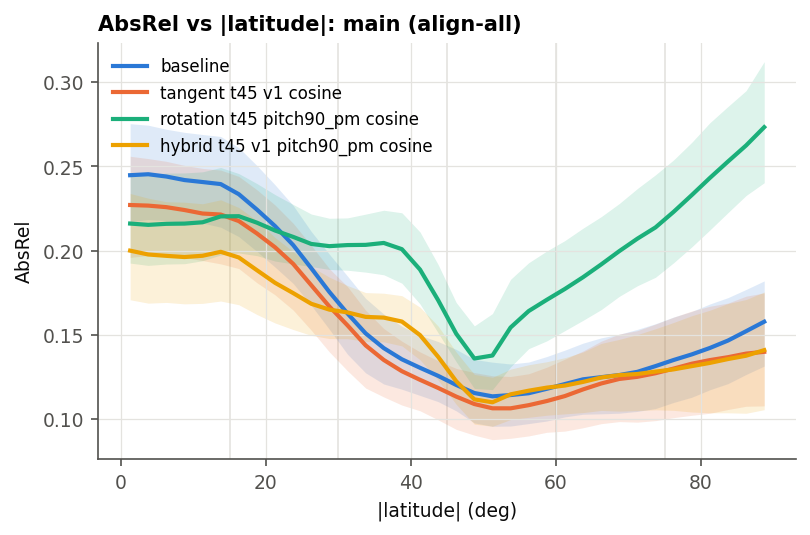

In [4]:
show('report_align-all/profile_main_align-all.png', 700)

### Latitude-specific improvement tables (paired over images; 95% bootstrap CI; Wilcoxon)

In [5]:
for name in ['tangent_plane', 'rotation', 'hybrid']:
    display(Markdown(f'**{name}** (eval alignment: all pixels)'))
    display(pd.read_csv(os.path.join(REP, f'{name}_improvement.csv')).round(4))
    display(Markdown(f'**{name}** (eval alignment fitted on |lat|<30 only)'))
    display(pd.read_csv(os.path.join(RES, 'report_align-equatorial', f'{name}_improvement.csv')).round(4))

**tangent_plane** (eval alignment: all pixels)

,band,baseline_abs_rel,corrected_abs_rel,improvement_%,per_image_impr_mean_%,ci95_lo_%,ci95_hi_%,wilcoxon_p,n_images,baseline_median_abs_rel,corrected_median_abs_rel,median_per_image_impr_%,images_improved
0,all,0.1630,0.1533,5.9967,6.8171,-0.2598,14.0471,0.0951,24,0.1557,0.1592,2.4021,16
1,0-15,0.2427,0.2245,7.4913,7.8263,3.1404,12.6969,0.0087,24,0.2288,0.2115,7.6119,18
2,15-30,0.2068,0.1947,5.8466,6.3640,1.6624,11.1910,0.0491,24,0.1930,0.1837,5.7014,17
3,30-45,0.1415,0.1344,5.0150,4.4951,-2.3291,12.0440,0.2182,24,0.1434,0.1368,1.2707,16
4,45-60,0.1162,0.1091,6.1295,5.2335,-5.5589,16.4019,0.3596,24,0.1074,0.1028,5.4571,14
5,60-75,0.1259,0.1215,3.4879,3.0656,-12.1127,16.6823,0.6840,24,0.1066,0.1045,-2.2132,12
6,75-90,0.1453,0.1356,6.6826,4.8425,-16.1071,23.2703,0.4389,24,0.1314,0.1098,1.2614,13


**tangent_plane** (eval alignment fitted on |lat|<30 only)

,band,baseline_abs_rel,corrected_abs_rel,improvement_%,per_image_impr_mean_%,ci95_lo_%,ci95_hi_%,wilcoxon_p,n_images,baseline_median_abs_rel,corrected_median_abs_rel,median_per_image_impr_%,images_improved
0,all,0.2676,0.2487,7.0841,7.8871,-0.3806,15.8097,0.1074,24,0.2285,0.2213,9.0880,15
1,0-15,0.1535,0.1535,0.0000,0.0000,0.0000,0.0000,NaN,24,0.1436,0.1436,0.0000,0
2,15-30,0.1477,0.1477,0.0000,0.0000,0.0000,0.0000,NaN,24,0.1324,0.1324,0.0000,0
3,30-45,0.2049,0.2018,1.4910,1.8133,0.7592,2.9448,0.0035,24,0.1791,0.1702,1.4337,18
4,45-60,0.2955,0.2770,6.2570,7.5121,1.7152,13.5208,0.0894,24,0.2516,0.2296,2.2025,15
5,60-75,0.3726,0.3388,9.0900,8.2438,-5.5017,21.0364,0.1780,24,0.3211,0.2652,11.7123,15
6,75-90,0.4312,0.3730,13.5066,4.2910,-22.7261,27.2304,0.1011,24,0.3755,0.2782,19.9661,16


**rotation** (eval alignment: all pixels)

,band,baseline_abs_rel,corrected_abs_rel,improvement_%,per_image_impr_mean_%,ci95_lo_%,ci95_hi_%,wilcoxon_p,n_images,baseline_median_abs_rel,corrected_median_abs_rel,median_per_image_impr_%,images_improved
0,all,0.1630,0.2031,-24.5981,-29.2343,-43.2913,-16.0397,0.0008,24,0.1557,0.2036,-21.3867,6
1,0-15,0.2427,0.2168,10.6716,9.0003,0.0043,17.2617,0.0269,24,0.2288,0.2213,13.8807,15
2,15-30,0.2068,0.2107,-1.8571,-6.2527,-17.8635,4.2767,0.8115,24,0.1930,0.2201,-5.3839,11
3,30-45,0.1415,0.1955,-38.1429,-55.6218,-88.1577,-28.8545,0.0003,24,0.1434,0.1977,-38.7080,5
4,45-60,0.1162,0.1526,-31.3434,-44.0142,-67.2523,-23.3524,0.0048,24,0.1074,0.1435,-32.3835,5
5,60-75,0.1259,0.1957,-55.4370,-91.0280,-144.3520,-47.7389,0.0014,24,0.1066,0.1769,-56.9419,7
6,75-90,0.1453,0.2476,-70.4405,-99.5775,-141.2756,-63.3231,0.0001,24,0.1314,0.2631,-88.5557,5


... (2 outputs left out)

**hybrid** (eval alignment: all pixels)

,band,baseline_abs_rel,corrected_abs_rel,improvement_%,per_image_impr_mean_%,ci95_lo_%,ci95_hi_%,wilcoxon_p,n_images,baseline_median_abs_rel,corrected_median_abs_rel,median_per_image_impr_%,images_improved
0,all,0.1630,0.1512,7.2724,6.9062,0.3309,12.9495,0.0164,24,0.1557,0.1417,8.8598,18
1,0-15,0.2427,0.1979,18.4666,18.3570,10.7223,26.4866,0.0000,24,0.2288,0.1872,14.1314,21
2,15-30,0.2068,0.1790,13.4754,12.7223,3.3580,21.3033,0.0016,24,0.1930,0.1784,12.5711,19
3,30-45,0.1415,0.1550,-9.5520,-19.1605,-36.6323,-4.2126,0.1974,24,0.1434,0.1536,-5.0182,9
4,45-60,0.1162,0.1158,0.3149,-7.6861,-24.1464,6.4140,1.0000,24,0.1074,0.1146,1.7981,13
5,60-75,0.1259,0.1247,0.9465,-13.8549,-46.2121,9.3678,0.6431,24,0.1066,0.1106,9.1881,13
6,75-90,0.1453,0.1347,7.2560,1.8527,-23.2650,23.1863,0.2182,24,0.1314,0.1075,19.8029,15


**hybrid** (eval alignment fitted on |lat|<30 only)

,band,baseline_abs_rel,corrected_abs_rel,improvement_%,per_image_impr_mean_%,ci95_lo_%,ci95_hi_%,wilcoxon_p,n_images,baseline_median_abs_rel,corrected_median_abs_rel,median_per_image_impr_%,images_improved
0,all,0.2676,0.2015,24.7002,19.7756,3.8500,33.8588,0.0039,24,0.2285,0.1678,36.2790,18
1,0-15,0.1535,0.1535,0.0000,0.0000,0.0000,0.0000,NaN,24,0.1436,0.1436,0.0000,0
2,15-30,0.1477,0.1477,0.0000,0.0000,0.0000,0.0000,NaN,24,0.1324,0.1324,0.0000,0
3,30-45,0.2049,0.1880,8.2295,8.1226,5.3412,10.9181,0.0001,24,0.1791,0.1598,8.0545,21
4,45-60,0.2955,0.2016,31.7562,25.0706,6.2148,41.7742,0.0031,24,0.2516,0.1559,37.0220,20
5,60-75,0.3726,0.2455,34.1305,20.7333,-5.6136,45.1636,0.0105,24,0.3211,0.1885,49.4839,18
6,75-90,0.4312,0.2726,36.7873,15.1969,-25.1951,48.5523,0.0053,24,0.3755,0.1911,50.9906,19


### Ablations (Experiments 5-7)

In [6]:
cols = ['abs_rel','abs_rel_0-15','abs_rel_45-60','abs_rel_60-75','abs_rel_75-90','abs_rel_polar_60_90','d1','model_calls','runtime_ratio']
ab = pd.read_csv(os.path.join(REP, 'ablation.csv'), index_col=0)
for e, d in ab.groupby('experiment', sort=False):
    display(Markdown(f'**{e}**')); display(d[cols].round(4))

**E5_threshold**

,abs_rel,abs_rel_0-15,abs_rel_45-60,abs_rel_60-75,abs_rel_75-90,abs_rel_polar_60_90,d1,model_calls,runtime_ratio
method,,,,,,,,,
baseline,0.1630,0.2427,0.1162,0.1259,0.1453,0.1357,0.7432,1.0,1.0000
hybrid|t30|v1|pitch90_pm|cosine|prior,0.1458,0.1819,0.1209,0.1194,0.1231,0.1213,0.7743,5.0,3.8337
hybrid|t45|v1|pitch90_pm|cosine|prior,0.1512,0.1979,0.1158,0.1247,0.1347,0.1298,0.7663,5.0,3.8398
hybrid|t60|v1|pitch90_pm|cosine|prior,0.1496,0.2038,0.1350,0.1146,0.1273,0.1210,0.7765,5.0,3.8654
hybrid|t75|v1|pitch90_pm|cosine|prior,0.1551,0.2220,0.1187,0.1365,0.1290,0.1327,0.7715,5.0,3.8887
rotation|t30|pitch90_pm|cosine|prior,0.2068,0.2302,0.1570,0.1882,0.2358,0.2123,0.6164,3.0,3.0717
rotation|t45|pitch90_pm|cosine|prior,0.2031,0.2168,0.1526,0.1957,0.2476,0.2220,0.6059,3.0,3.0840
rotation|t60|pitch90_pm|cosine|prior,0.1926,0.2119,0.1489,0.1793,0.2592,0.2197,0.6372,3.0,3.1074
rotation|t75|pitch90_pm|cosine|prior,0.1775,0.2238,0.1251,0.1385,0.2402,0.1899,0.7094,3.0,3.1224


**E6_views**

,abs_rel,abs_rel_0-15,abs_rel_45-60,abs_rel_60-75,abs_rel_75-90,abs_rel_polar_60_90,d1,model_calls,runtime_ratio
method,,,,,,,,,
baseline,0.1630,0.2427,0.1162,0.1259,0.1453,0.1357,0.7432,1.0,1.0000
hybrid|t45|v1|pitch90_pm|cosine|prior,0.1512,0.1979,0.1158,0.1247,0.1347,0.1298,0.7663,5.0,3.8398
hybrid|t45|v2|pitch90_pm|cosine|prior,0.1463,0.1953,0.1108,0.1187,0.1251,0.1219,0.7895,7.0,4.7715
hybrid|t45|v3|pitch90_pm|cosine|prior,0.1414,0.1983,0.1116,0.1101,0.1215,0.1158,0.8046,9.0,5.5001
hybrid|t45|v5|pitch90_pm|cosine|prior,0.1501,0.2036,0.1092,0.1242,0.1495,0.1370,0.7794,13.0,7.1913
tangent|t45|v1|cosine|prior,0.1533,0.2245,0.1091,0.1215,0.1356,0.1286,0.7660,3.0,1.7602
tangent|t45|v2|cosine|prior,0.1516,0.2206,0.1181,0.1222,0.1224,0.1223,0.7810,5.0,2.6901
tangent|t45|v3|cosine|prior,0.1485,0.2215,0.1128,0.1148,0.1238,0.1194,0.7857,7.0,3.4219
tangent|t45|v5|cosine|prior,0.1604,0.2247,0.1170,0.1367,0.1564,0.1467,0.7435,11.0,5.1120


**E7_fusion**

,abs_rel,abs_rel_0-15,abs_rel_45-60,abs_rel_60-75,abs_rel_75-90,abs_rel_polar_60_90,d1,model_calls,runtime_ratio
method,,,,,,,,,
baseline,0.1630,0.2427,0.1162,0.1259,0.1453,0.1357,0.7432,1.0,1.0000
hybrid|t45|v1|pitch90_pm|confidence|prior,0.1595,0.2400,0.1094,0.1281,0.1350,0.1316,0.7568,5.0,3.9067
hybrid|t45|v1|pitch90_pm|cosine|prior,0.1512,0.1979,0.1158,0.1247,0.1347,0.1298,0.7663,5.0,3.8398
hybrid|t45|v1|pitch90_pm|hard|prior,0.1536,0.1971,0.1194,0.1247,0.1343,0.1295,0.7563,5.0,3.8394
hybrid|t45|v1|pitch90_pm|linear|prior,0.1506,0.1980,0.1151,0.1250,0.1351,0.1301,0.7695,5.0,3.8390
hybrid|t45|v1|pitch90_pm|polynomial|prior,0.1531,0.1983,0.1206,0.1281,0.1365,0.1323,0.7601,5.0,3.8365
hybrid|t45|v1|pitch90_pm|sigmoid|prior,0.1511,0.1979,0.1149,0.1247,0.1348,0.1298,0.7662,5.0,3.8377
rotation|t45|pitch90_pm|confidence|prior,0.1864,0.2488,0.1394,0.1672,0.1866,0.1770,0.6744,3.0,3.1291
rotation|t45|pitch90_pm|cosine|prior,0.2031,0.2168,0.1526,0.1957,0.2476,0.2220,0.6059,3.0,3.0840


... (4 outputs left out)

**E3_rotation_sets**

,abs_rel,abs_rel_0-15,abs_rel_45-60,abs_rel_60-75,abs_rel_75-90,abs_rel_polar_60_90,d1,model_calls,runtime_ratio
method,,,,,,,,,
baseline,0.1630,0.2427,0.1162,0.1259,0.1453,0.1357,0.7432,1.0,1.0000
rotation|t45|pitch45_pm|confidence|prior,0.1923,0.2409,0.1416,0.1751,0.2137,0.1946,0.6403,3.0,3.1470
rotation|t45|pitch45_pm|cosine|prior,0.2068,0.2268,0.1560,0.2064,0.2352,0.2210,0.5958,3.0,3.1047
rotation|t45|pitch90_pm|confidence|prior,0.1864,0.2488,0.1394,0.1672,0.1866,0.1770,0.6744,3.0,3.1291
rotation|t45|pitch90_pm|cosine|prior,0.2031,0.2168,0.1526,0.1957,0.2476,0.2220,0.6059,3.0,3.0840
rotation|t45|pitch90_x4|confidence|prior,0.1705,0.2052,0.1314,0.1520,0.1775,0.1649,0.7088,5.0,5.1982
rotation|t45|pitch90_x4|cosine|prior,0.1916,0.1984,0.1411,0.1849,0.2330,0.2092,0.6330,5.0,5.1263
rotation|t45|pitch90|confidence|prior,0.1847,0.2316,0.1188,0.1657,0.2366,0.2016,0.6608,2.0,2.0756
rotation|t45|pitch90|cosine|prior,0.1890,0.2133,0.1431,0.1834,0.2049,0.1943,0.6319,2.0,2.0454


**E4_hybrid_control**

,abs_rel,abs_rel_0-15,abs_rel_45-60,abs_rel_60-75,abs_rel_75-90,abs_rel_polar_60_90,d1,model_calls,runtime_ratio
method,,,,,,,,,
baseline,0.1630,0.2427,0.1162,0.1259,0.1453,0.1357,0.7432,1.0,1.0000
hybrid|t45|v1|pitch90_pm|cosine|prior,0.1512,0.1979,0.1158,0.1247,0.1347,0.1298,0.7663,5.0,3.8398
hybrid|t45|v1|yaw_only_x3|cosine|prior,0.1541,0.2269,0.1106,0.1227,0.1343,0.1286,0.7689,6.0,4.9613


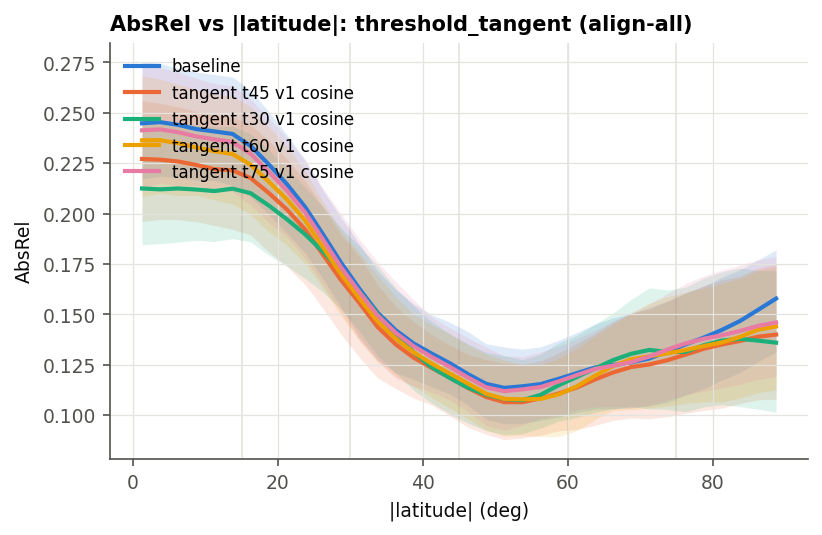

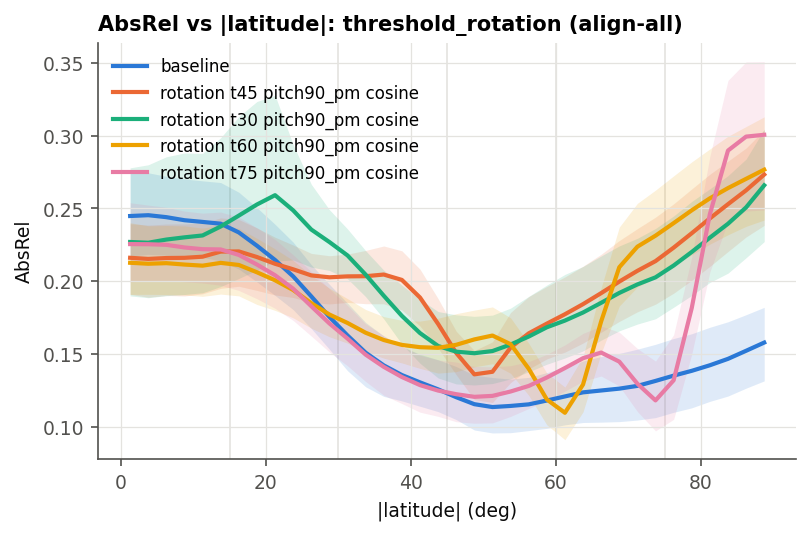

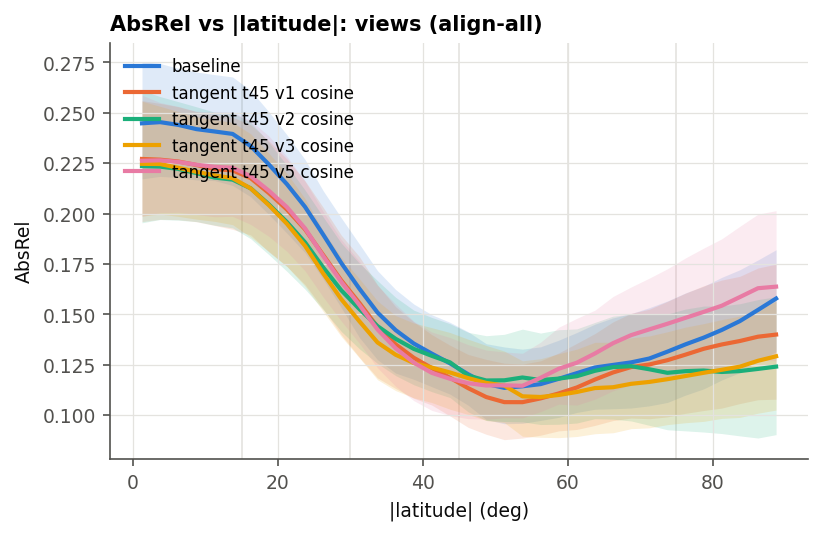

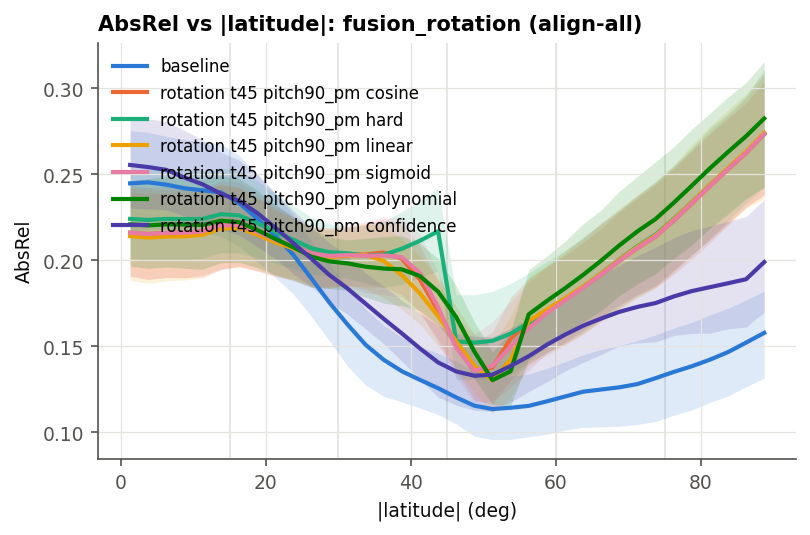

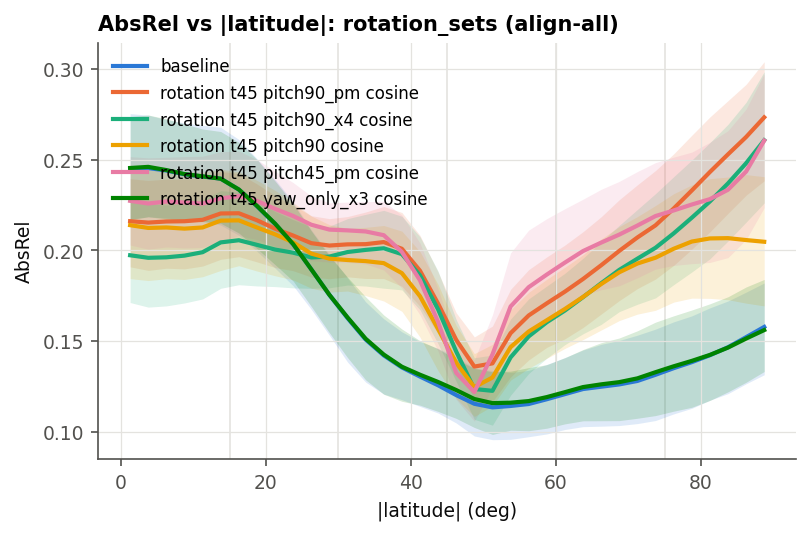

In [7]:
for f in ['profile_threshold_tangent', 'profile_threshold_rotation', 'profile_views', 'profile_fusion_rotation', 'profile_rotation_sets']:
    show(f'report_align-all/{f}_align-all.png', 650)

### Resolution (Experiment 8) and runtime (Experiment 9)

,resolution,abs_rel,sq_rel,rmse,rmse_log,mae,medae,d1,d2,d3,pct_bad,abs_rel_0-15,abs_rel_15-30,abs_rel_30-45,abs_rel_45-60,abs_rel_60-75,abs_rel_75-90,abs_rel_polar_60_90,runtime_s,model_calls,runtime_ratio
method,,,,,,,,,,,,,,,,,,,,,
baseline,256x512,0.1609,0.1098,0.5815,0.2157,0.3771,0.2431,0.7189,0.9454,0.9909,56.0785,0.2392,0.2080,0.1354,0.1191,0.1249,0.1380,0.1313,1.8261,1.0,1.0000
tangent|t45|v1|cosine|prior,256x512,0.1621,0.1065,0.5616,0.2108,0.3776,0.2592,0.7146,0.9565,0.9926,59.3239,0.2222,0.1963,0.1337,0.1217,0.1394,0.1590,0.1490,5.6940,3.0,3.1181
rotation|t45|pitch90_pm|cosine|prior,256x512,0.2160,0.1863,0.7271,0.2662,0.4893,0.3545,0.5829,0.9096,0.9845,72.4246,0.2219,0.2224,0.2238,0.1497,0.2119,0.2662,0.2384,5.1865,3.0,2.8401
hybrid|t45|v1|pitch90_pm|cosine|prior,256x512,0.1569,0.0980,0.5245,0.2008,0.3601,0.2559,0.7413,0.9622,0.9973,59.2148,0.1894,0.1783,0.1704,0.1145,0.1354,0.1535,0.1443,9.0544,5.0,4.9582
baseline,384x768,0.1611,0.1067,0.5798,0.2144,0.3769,0.2404,0.7343,0.9460,0.9913,58.1764,0.2387,0.2052,0.1406,0.1251,0.1218,0.1350,0.1284,4.7323,1.0,1.0000
tangent|t45|v1|cosine|prior,384x768,0.1459,0.0903,0.5174,0.1926,0.3379,0.2237,0.7594,0.9618,0.9941,53.1626,0.2185,0.1872,0.1300,0.1156,0.1085,0.1154,0.1119,8.5856,3.0,1.8143
rotation|t45|pitch90_pm|cosine|prior,384x768,0.2076,0.1526,0.6533,0.2554,0.4631,0.3396,0.5853,0.9232,0.9921,70.1116,0.2091,0.2136,0.1904,0.1615,0.2161,0.2550,0.2355,15.6268,3.0,3.3022
hybrid|t45|v1|pitch90_pm|cosine|prior,384x768,0.1445,0.0800,0.4726,0.1850,0.3273,0.2378,0.7617,0.9756,0.9967,54.9347,0.1792,0.1692,0.1544,0.1181,0.1225,0.1233,0.1229,19.4551,5.0,4.1112
baseline,512x1024,0.1647,0.1108,0.5907,0.2191,0.3854,0.2508,0.7423,0.9397,0.9896,61.7069,0.2456,0.2098,0.1491,0.1330,0.1206,0.1302,0.1254,12.2061,1.0,1.0000


,wall_s,model_calls,model_time_s,post_time_s,peak_gpu_mem_mb,overhead_x
method,,,,,,
baseline,5.559,1.0,5.553,0.001,NaN,1.000
tangent|t45|v1|cosine|prior,9.058,3.0,8.808,0.237,NaN,1.629
rotation|t45|pitch90_pm|cosine|prior,16.147,3.0,15.720,0.423,NaN,2.905
hybrid|t45|v1|pitch90_pm|cosine|prior,19.963,5.0,19.341,0.610,NaN,3.591
tangent|t45|v2|cosine|prior,13.970,5.0,13.372,0.459,NaN,2.513
tangent|t45|v3|cosine|prior,17.953,7.0,17.179,0.746,NaN,3.229
tangent|t45|v5|cosine|prior,26.724,11.0,25.568,1.122,NaN,4.807


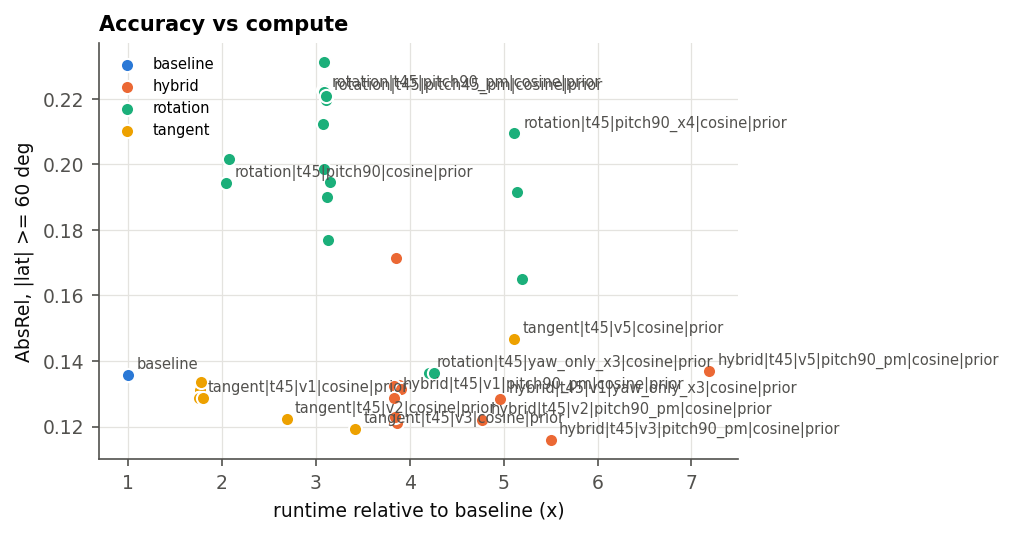

In [8]:
display(pd.read_csv(os.path.join(RES, 'resolution.csv'), index_col=0).round(4))
display(pd.read_csv(os.path.join(RES, 'runtime_cold.csv'), index_col=0).round(3))
show('report_align-all/runtime_vs_accuracy.png', 650)

### Qualitative

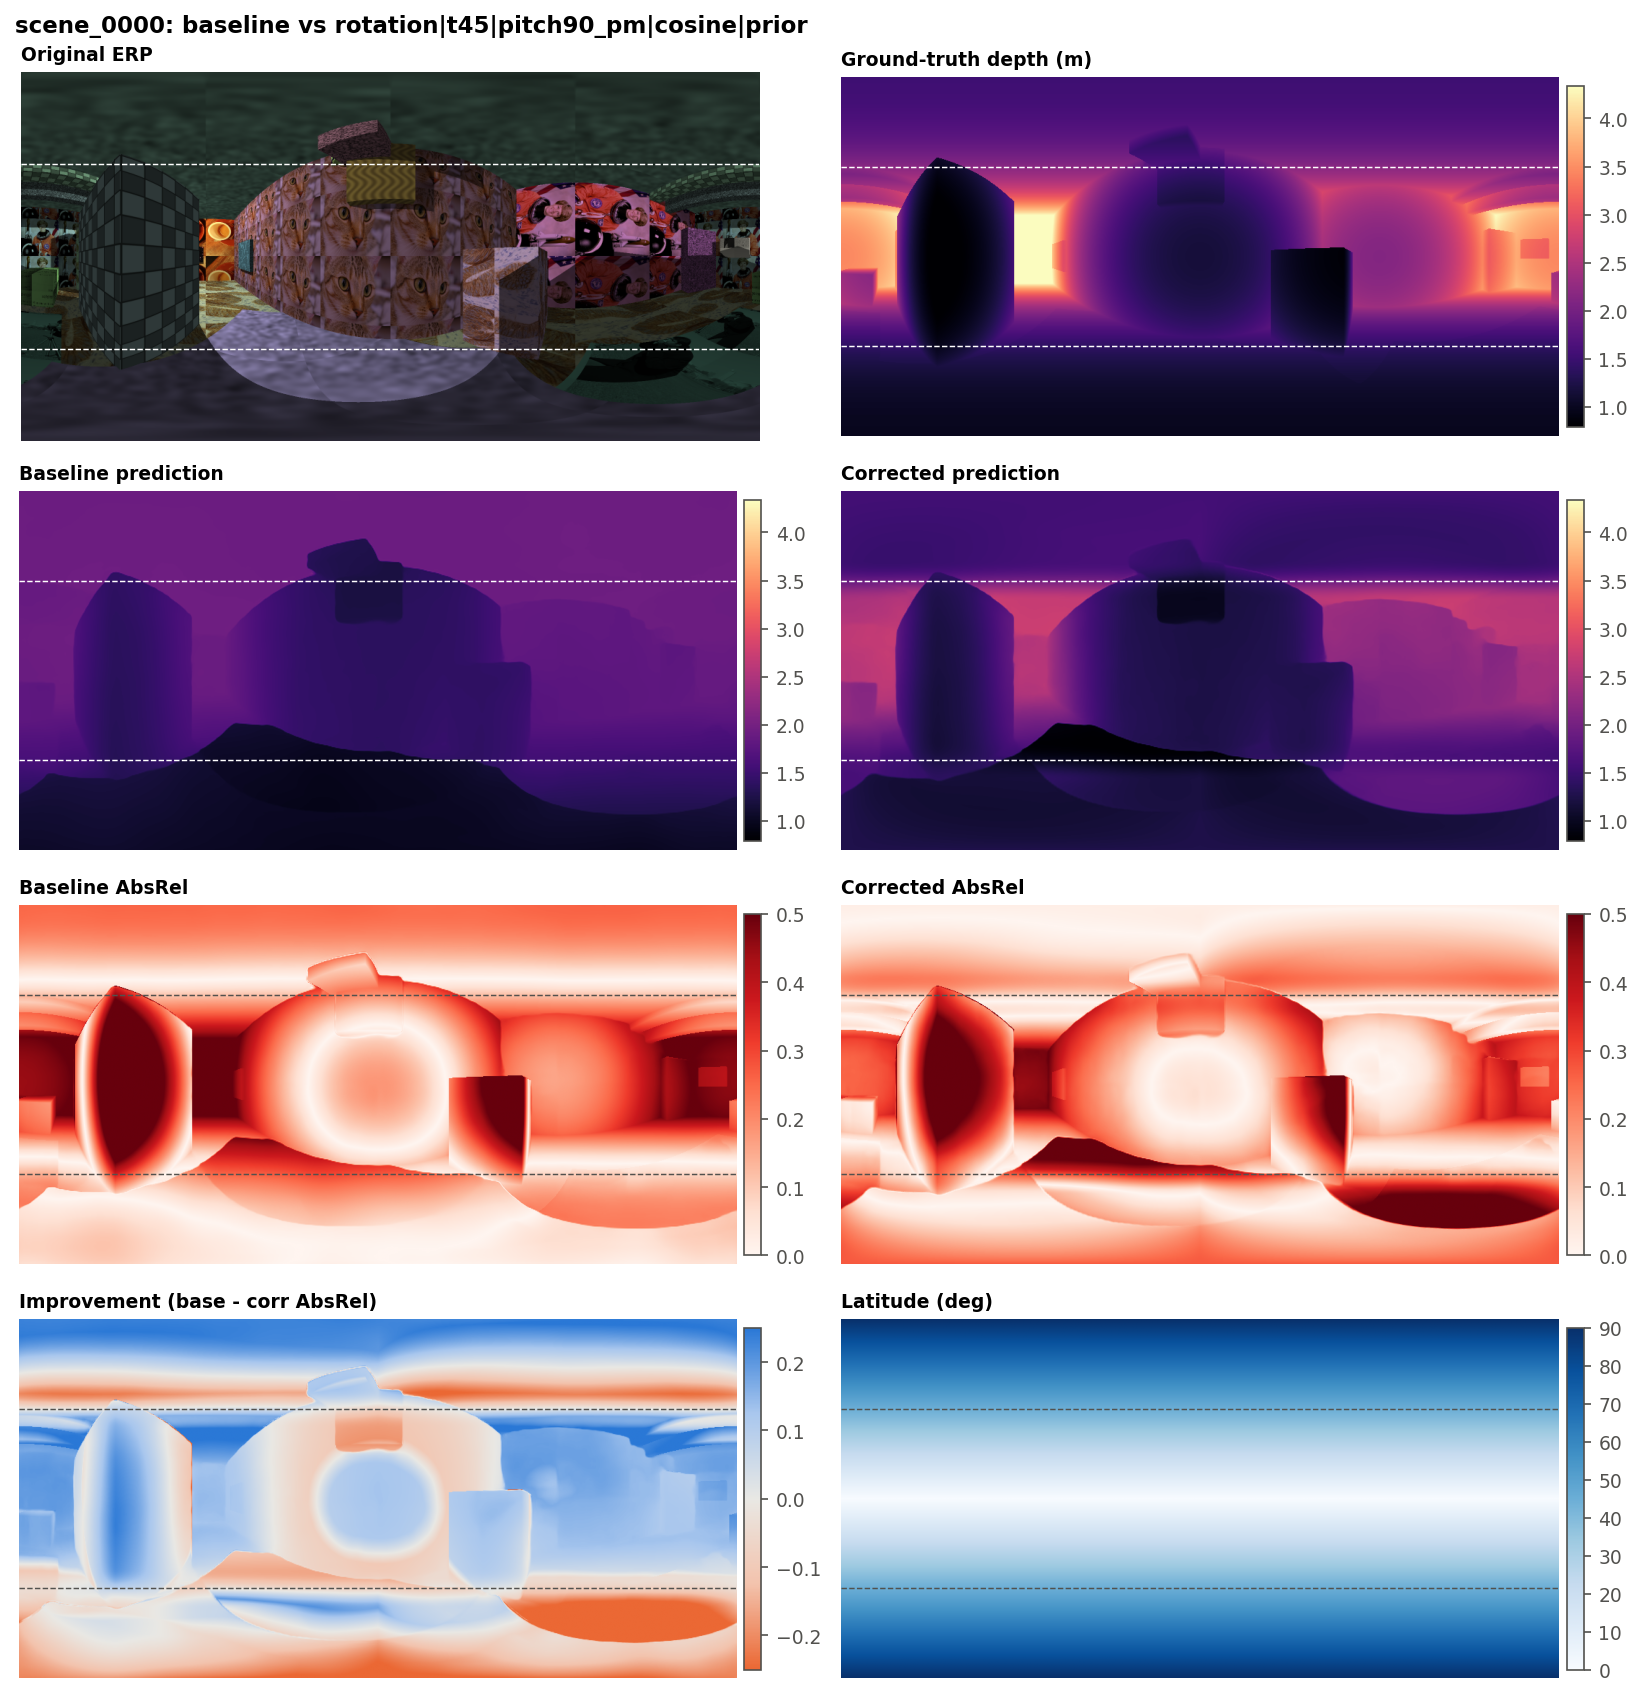

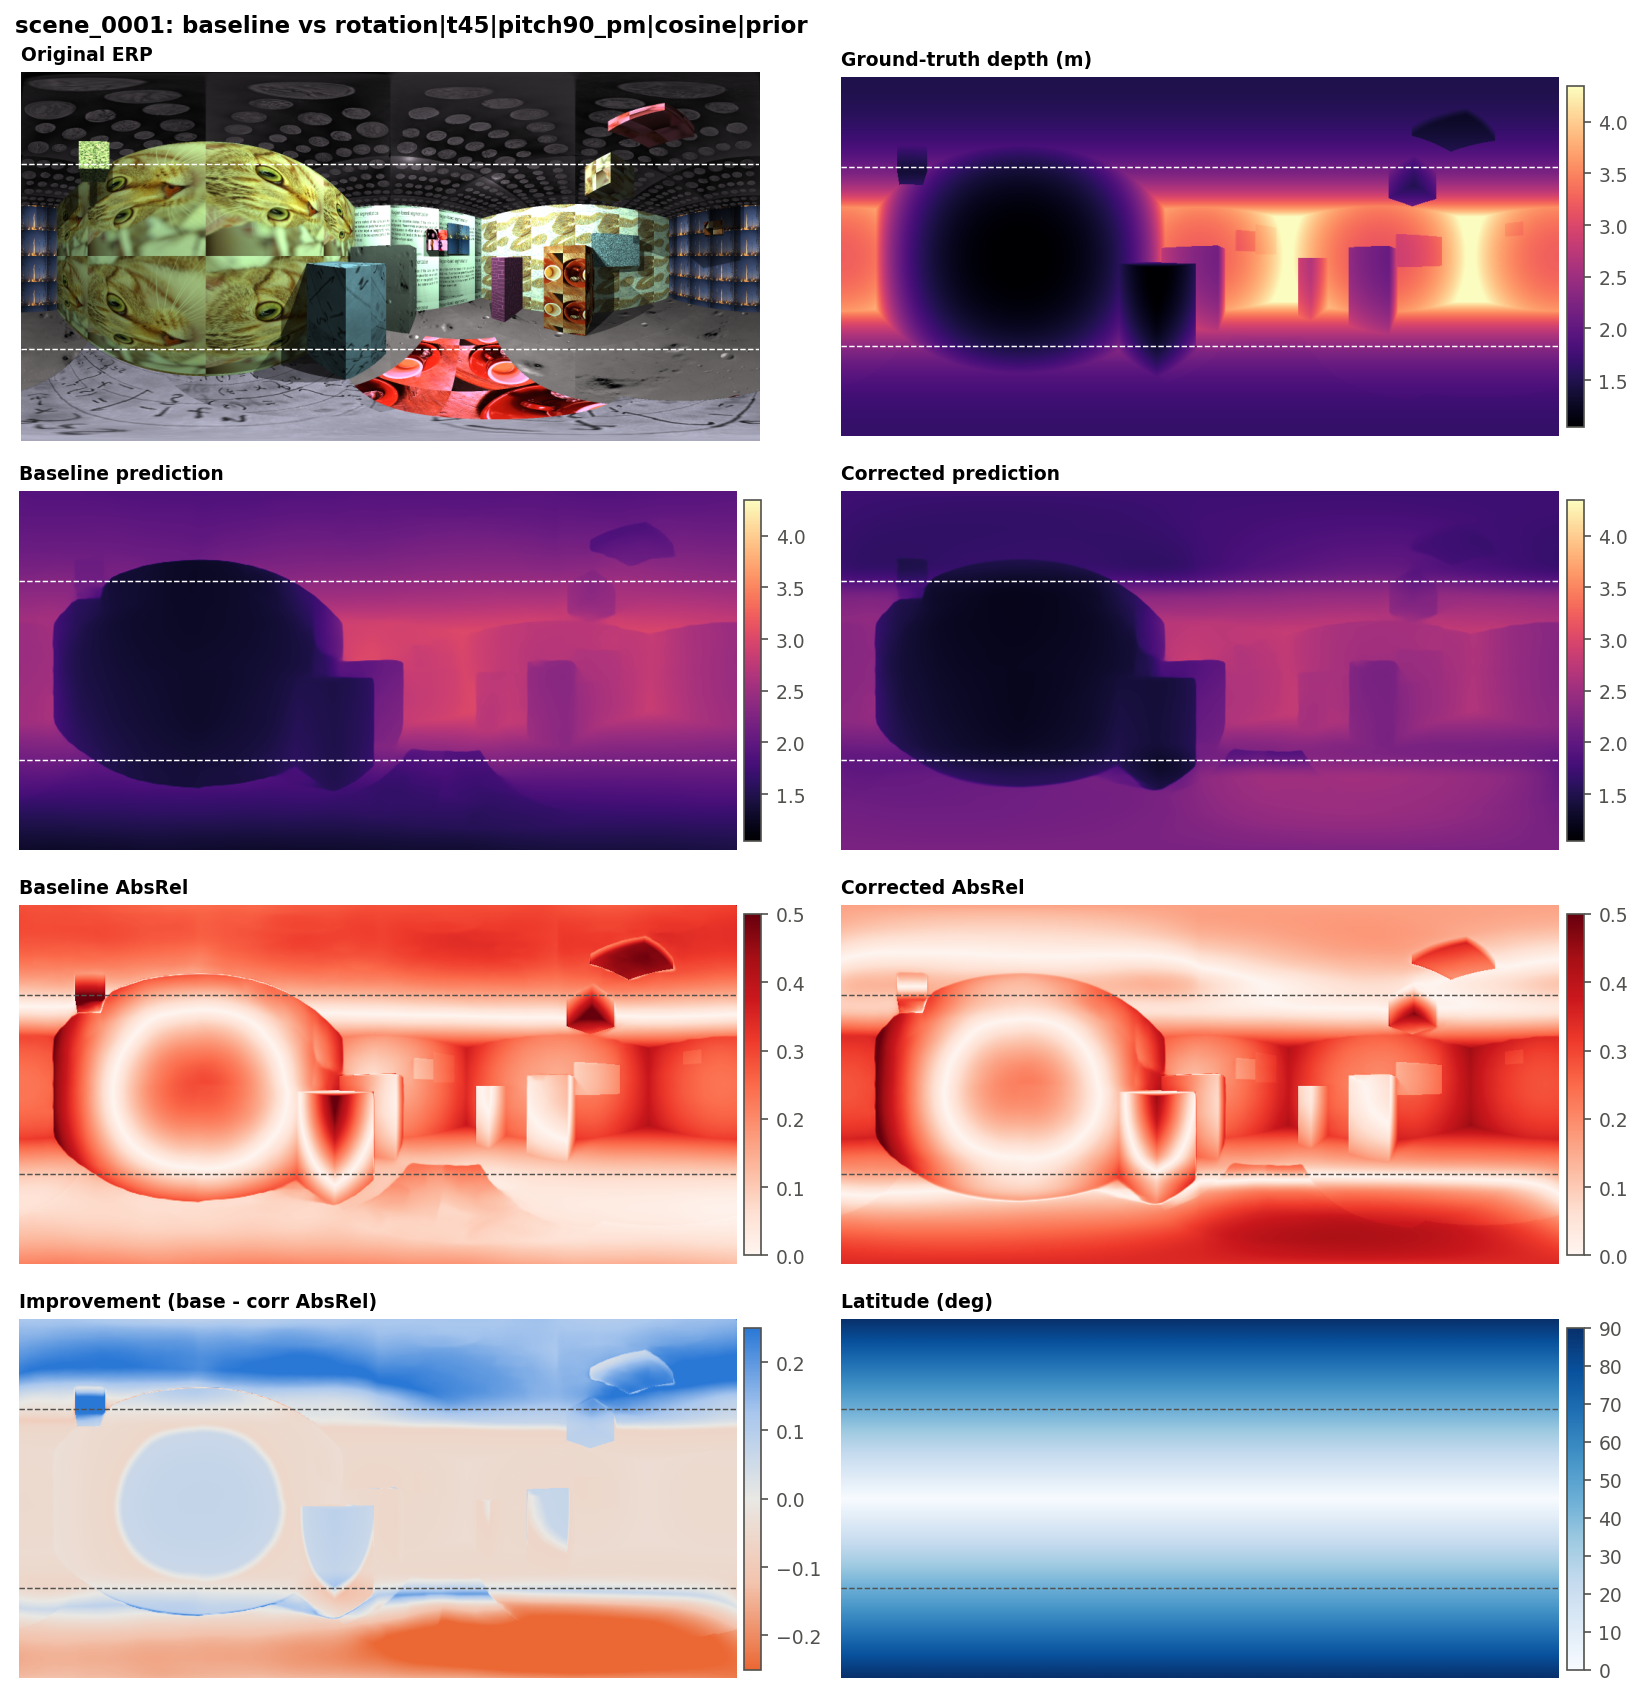

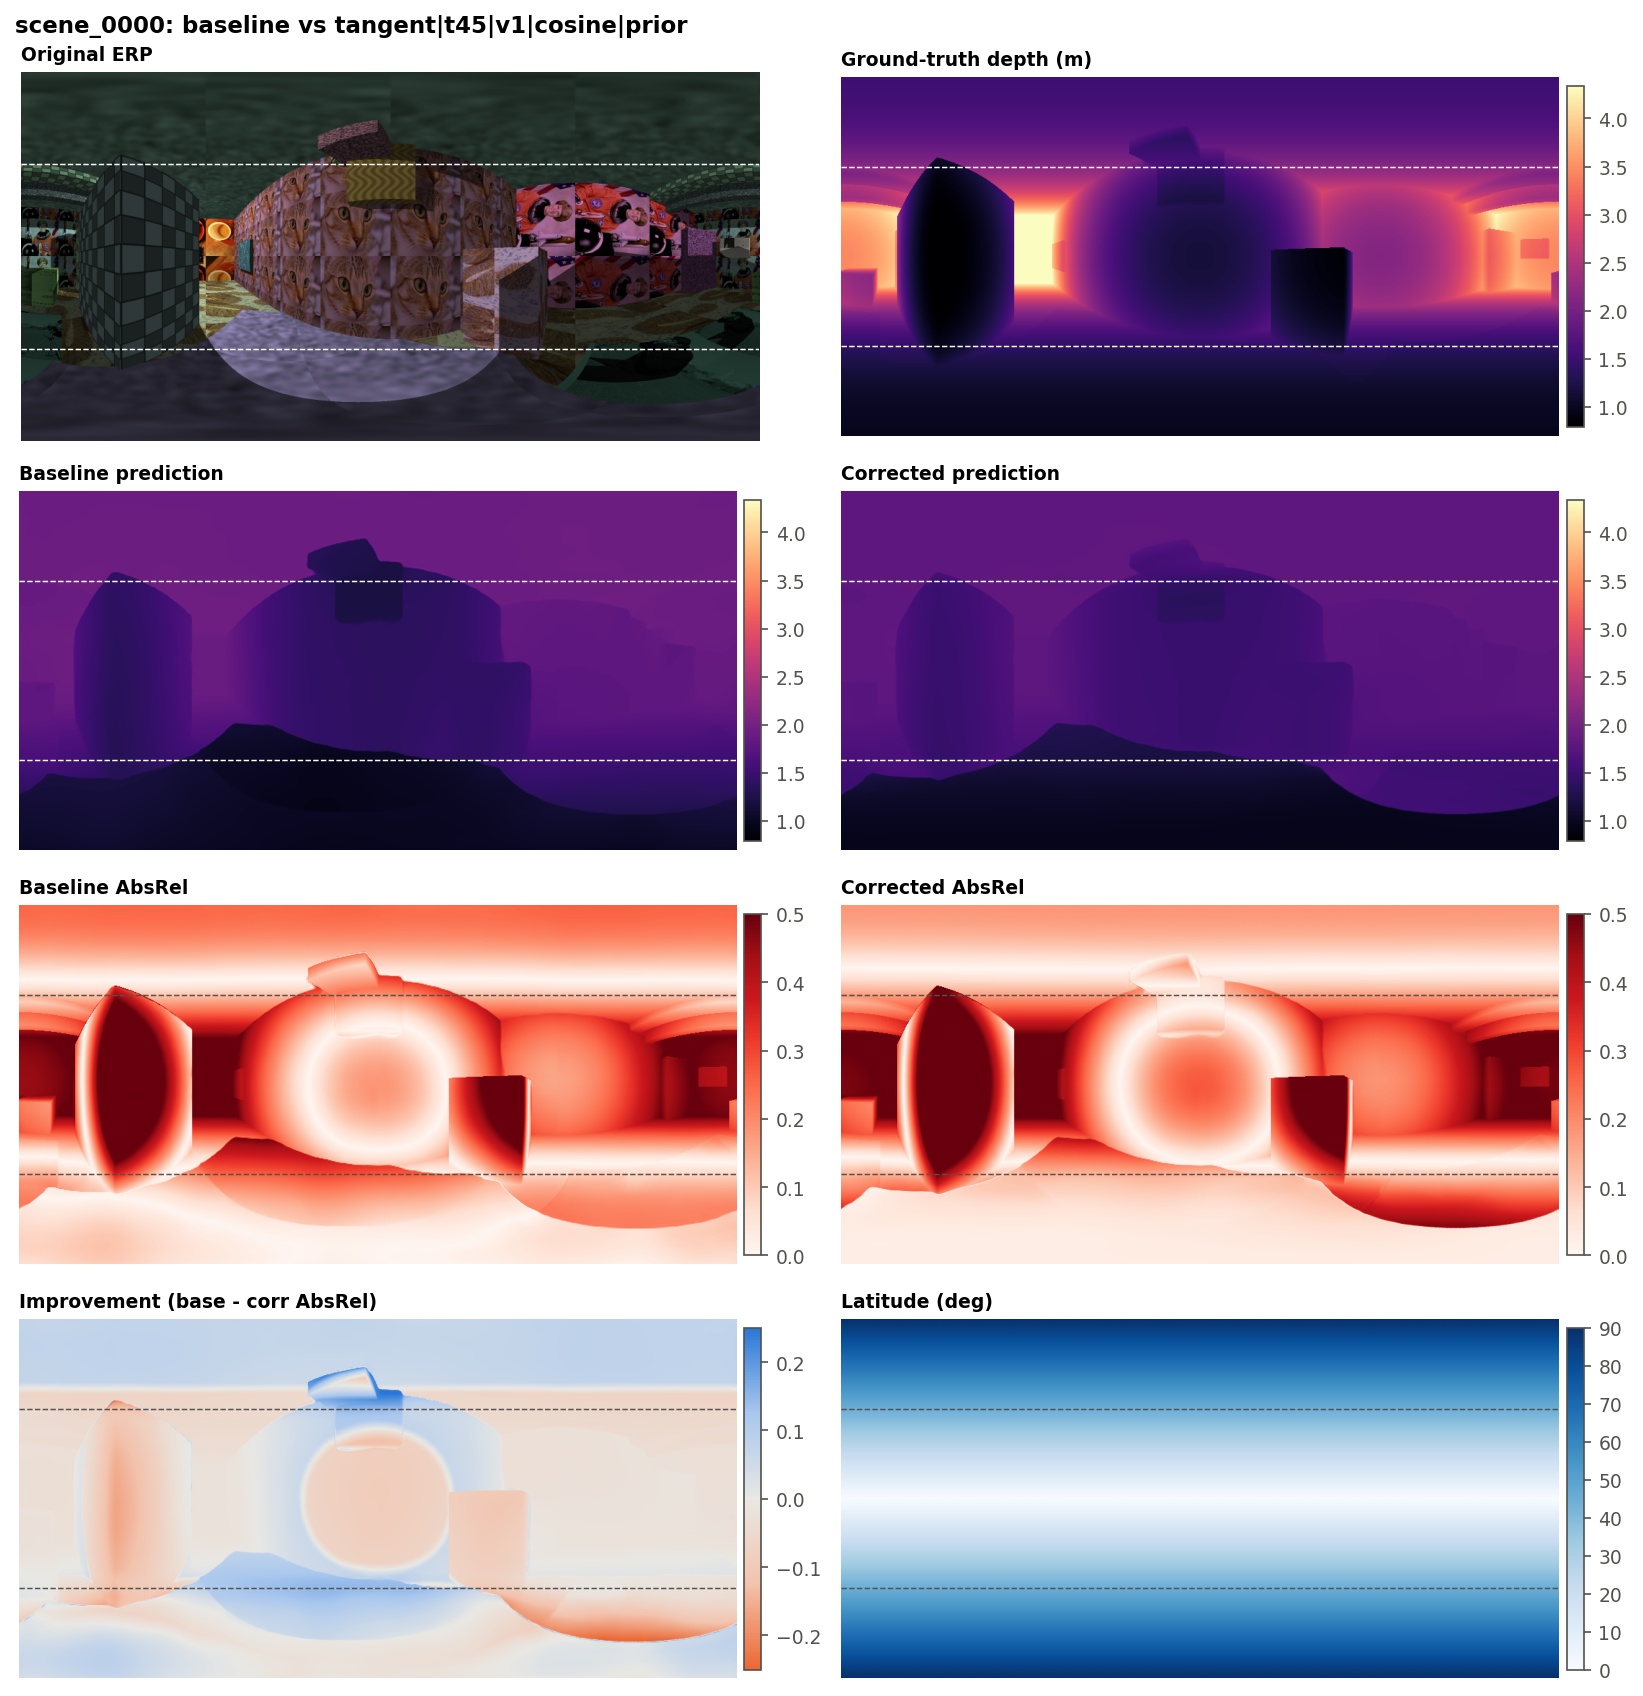

In [9]:
import glob
for p in sorted(glob.glob(os.path.join(RES, 'qualitative', 'scene_*_rotation.png')))[:2]: show(p, 900)
for p in sorted(glob.glob(os.path.join(RES, 'qualitative', 'scene_*_tangent.png')))[:1]: show(p, 900)

### Error heatmaps (same colour scale)

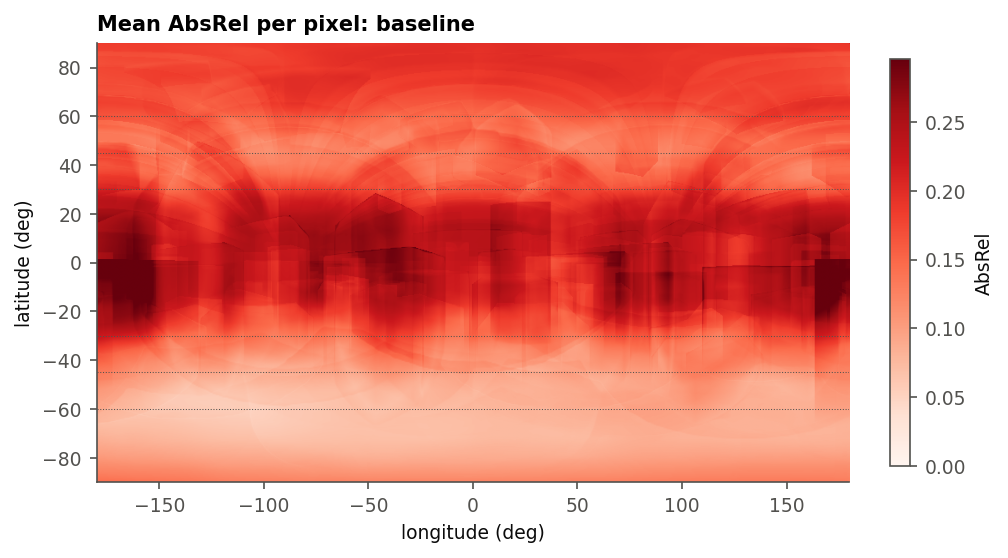

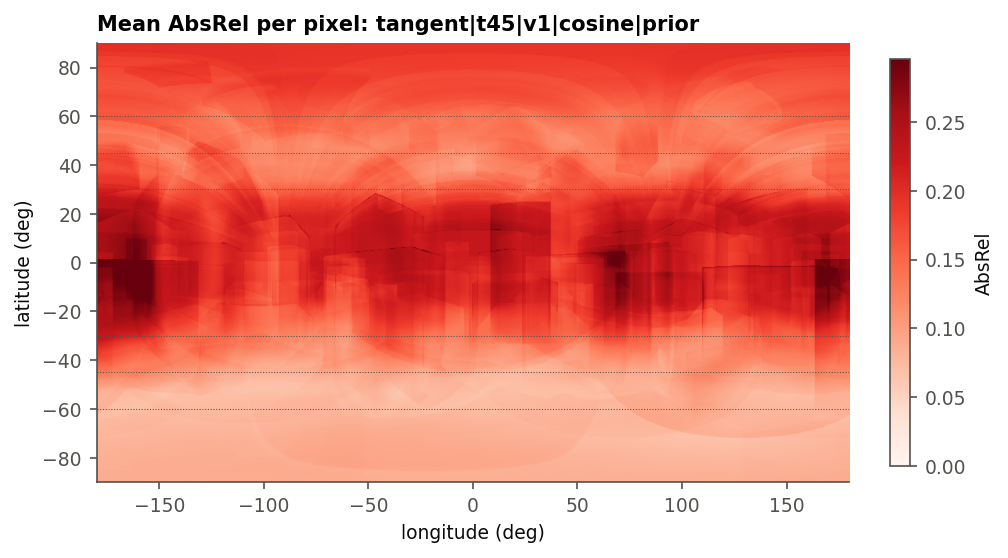

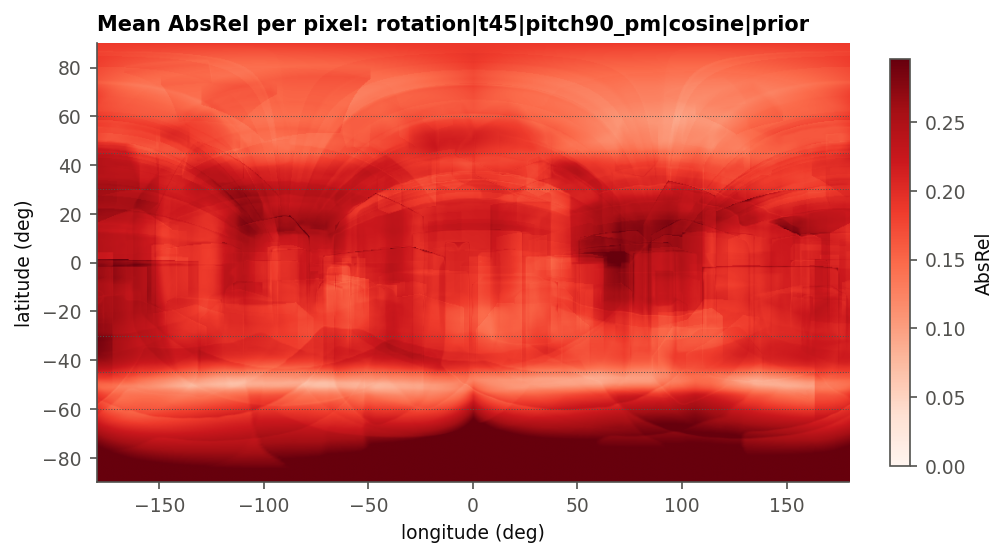

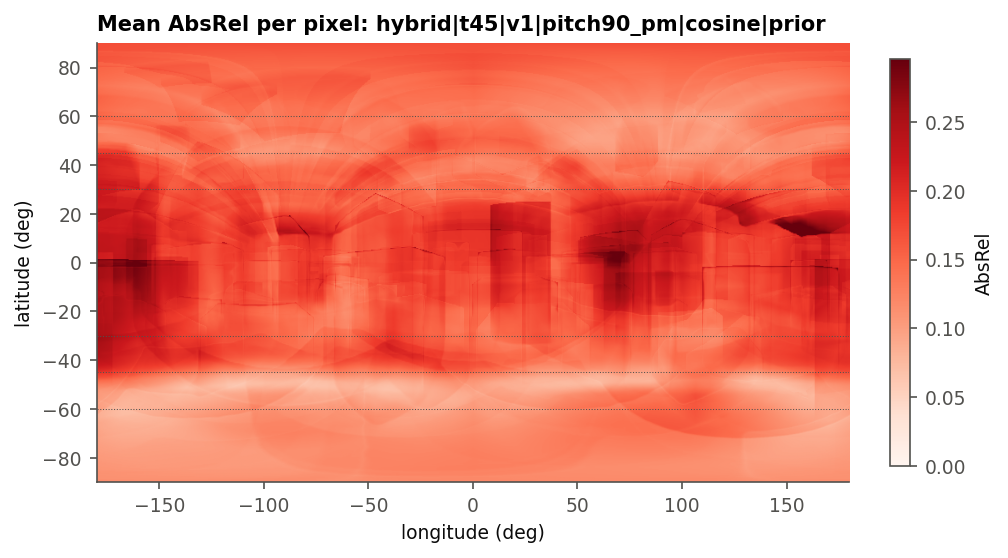

In [10]:
for m in ['baseline', 'tangent', 'rotation', 'hybrid']: show(f'report_align-all/heatmap_{m}.png', 650)